# 01 — Hồ sơ dữ liệu (Data Profiling)

**Mục tiêu:** nắm cấu trúc, kích thước, mức độ đầy đủ và các vấn đề chất lượng của **6 file CSV nguồn**
trong bộ dữ liệu *Vendor Performance Analysis* (chuỗi bán lẻ rượu, năm 2024).

> **Nguồn dữ liệu:** chỉ các CSV trong `data/raw/` (`begin_inventory`, `end_inventory`, `purchase_prices`,
> `purchases`, `sales`, `vendor_invoice`). **Không dùng** `inventory.db`. `vendor_sales_summary.csv` chỉ được
> nạp làm bảng tham chiếu để **kiểm chứng** kết quả tự tính (mục 7).

**Cách chạy nhanh:** CSV được nạp 1 lần vào `data/interim/staging.db` (`sql/staging/00_schema.sql`);
mọi truy vấn nặng (quét 12,8 triệu dòng `sales`) được gom vào `sql/build/*.sql` và chỉ chạy **một lần**
để tạo `data/processed/analytics.db`.
Notebook chỉ gọi các truy vấn nhỏ trong `sql/queries/` qua `dl.query(...)`.

| Bước | Nội dung |
|---|---|
| 1 | Dựng / kiểm tra `analytics.db` |
| 2 | Tổng quan bảng (số dòng, số cột, ô null) |
| 3 | Hồ sơ từng cột: null, số giá trị khác nhau, giá trị 0, khoảng trắng thừa |
| 4 | Danh mục vấn đề chất lượng dữ liệu |
| 5 | Kiểm tra ngày tháng: định dạng, phạm vi, ngày thiếu |
| 6 | Nhất quán giữa các file: khóa, tồn kho, thuộc tính, giá, hóa đơn |
| 7 | Kiểm chứng bảng tự tính với `vendor_sales_summary.csv` (chỉ tham chiếu) |

## 0. Thiết lập môi trường
Thêm thư mục gốc dự án vào `sys.path` để import package `src`, nạp thư viện và áp dụng
phong cách biểu đồ xuất bản (bảng màu **đậm**) dùng chung cho mọi notebook.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl, preprocessing as pp, visualization as viz
from src.config import TABLE_DIR
from src.visualization import PALETTE, CLASS_COLORS

viz.set_style()
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Dựng hoặc dùng lại `analytics.db`
`build_marts()` nạp CSV → `staging.db` (nếu chưa có), rồi chạy lần lượt `sql/build/01…08_*.sql`
+ profiling (lần đầu ~10 phút).
Nếu file đã có thì dùng lại ngay; truyền `force=True` khi sửa SQL build.

In [2]:
dl.build_marts()

analytics.db đã có (88.6 MB) — dùng lại. Gọi build_marts(force=True) để dựng lại.


WindowsPath('D:/2026.1/Kho dữ liệu/data/processed/analytics.db')

Danh mục bảng trong `analytics.db` và số dòng — kiểm tra mọi mart đã được tạo, kích thước
đều nhỏ (tối đa vài trăm nghìn dòng) nên đọc vào pandas rất nhanh.

In [3]:
catalog = dl.mart_catalog()
catalog

,table_name,n_rows
0,build_info,1
1,dim_product,12261
2,dim_store,80
3,dim_vendor,132
4,dq_calendar,366
5,dq_checks,24
6,dq_consistency,39
7,dq_dates,10
8,map_invoice_po,5543
9,mart_inventory,256042


Danh sách truy vấn có sẵn trong `sql/queries/` (dòng đầu mỗi file là mô tả) — đây là
“menu” dùng chung cho cả 4 notebook.

In [4]:
dl.list_queries()

,query,mô tả
0,classification_summary,"So sánh 2 nhóm sản phẩm: số SP, doanh thu, tiề..."
1,dq_calendar,Lịch 366 ngày năm 2024: có dữ liệu bán / nhận ...
2,dq_checks,Danh sách vấn đề chất lượng dữ liệu kèm tỷ lệ ...
3,dq_consistency,"Kiểm tra nhất quán giữa các file CSV (nhóm, số..."
4,dq_dates,"Hồ sơ các cột ngày: định dạng sai, min/max, số..."
5,inventory_items,Tồn kho đầu/cuối kỳ cấp InventoryId (chỉ cột s...
6,inventory_status,Số mặt hàng theo trạng thái tồn kho × nhóm sản...
7,invoice_match,"Kết quả ghép hóa đơn ↔ PO: loại ghép, độ lệch ..."
8,invoice_shift,Độ lệch PODate (hóa đơn − dòng mua) của từng h...
9,mart_catalog,"Danh mục bảng trong analytics.db (dim_*, mart_..."


## 2. Tổng quan 6 bảng nguồn (CSV)

Số dòng, số cột, tổng số ô null và % ô null của từng file CSV nguồn (lấy từ `profile_columns`
— đã tính sẵn khi build).

In [5]:
tables = dl.query("profile_tables")
tables.to_csv(TABLE_DIR / "01_table_overview.csv", index=False)
pp.style_table(tables, num=["n_rows", "n_columns", "n_null_cells", "n_cols_untrimmed"], dec=["null_cell_pct"])

table_name,n_rows,n_columns,n_null_cells,null_cell_pct,n_cols_untrimmed
sales,"12,825,363",14,0,0.00,1
purchases,"2,372,474",16,3,0.00,1
end_inventory,"224,489",9,"1,284",0.06,0
begin_inventory,"206,529",9,0,0.00,0
purchase_prices,"12,261",9,3,0.00,1
vendor_invoice,"5,543",10,"5,169",9.33,1


**Biểu đồ 1.1 — Quy mô bảng.** Trục x thang log vì `sales` lớn hơn `vendor_invoice` ~2 300 lần.
Màu đậm phân biệt bảng giao dịch (xanh) và bảng danh mục/tổng hợp (đỏ rượu).

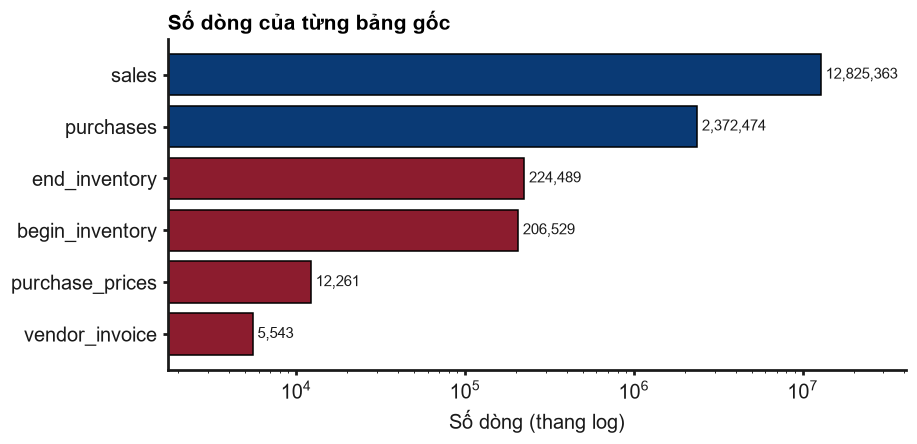

In [6]:
transactional = {"sales", "purchases"}
colors = [PALETTE["blue"] if t in transactional else PALETTE["wine"] for t in tables["table_name"]]
fig, (ax,) = viz.new_figure(figsize=(8.5, 4.2))
viz.barh(ax, tables["table_name"], tables["n_rows"], color=colors, annotate="{:,.0f}")
ax.set_xscale("log")
viz.label(ax, "Số dòng của từng bảng gốc", "Số dòng (thang log)")
viz.save_figure(fig, "01_table_rows")
plt.show()

## 3. Hồ sơ từng cột

Bảng hồ sơ đầy đủ cho mọi cột của mọi bảng: kiểu khai báo, % null, số giá trị khác nhau,
số giá trị 0, số chuỗi có khoảng trắng thừa, min/max/mean. Lưu ra `reports/table/` để tra cứu.

In [7]:
profile = dl.query("profile_columns", table="*")
profile.to_csv(TABLE_DIR / "01_column_profile.csv", index=False)
profile.drop(columns=["ordinal"]).head(30)

,table_name,column_name,declared_type,n_rows,n_null,null_pct,n_distinct,distinct_pct,n_zero,n_untrimmed,min_value,max_value,mean_value
0,begin_inventory,InventoryId,TEXT,206529,0,0.00,206529,100.00,0,0,10_HORNSEY_1000,9_BLACKPOOL_999,NaN
1,begin_inventory,Store,BIGINT,206529,0,0.00,79,0.04,0,0,1,79,42.12
2,begin_inventory,City,TEXT,206529,0,0.00,67,0.03,0,0,ABERDEEN,WOLFORD,NaN
3,begin_inventory,Brand,BIGINT,206529,0,0.00,8094,3.92,0,0,58,90090,"13,761.48"
4,begin_inventory,Description,TEXT,206529,0,0.00,7291,3.53,0,0,(RI) 1,von Buhl Jazz Rsl,NaN
5,begin_inventory,Size,TEXT,206529,0,0.00,41,0.02,0,0,1.5L,Liter,NaN
6,begin_inventory,onHand,BIGINT,206529,0,0.00,474,0.23,6044,0,0,1251,20.43
7,begin_inventory,Price,FLOAT,206529,0,0.00,329,0.16,2,0,0.0,13999.9,22.25
8,begin_inventory,startDate,TEXT,206529,0,0.00,1,0.00,0,0,2024-01-01,2024-01-01,NaN
9,end_inventory,InventoryId,TEXT,224489,0,0.00,224489,100.00,0,0,10_HORNSEY_1001,9_BLACKPOOL_984,NaN


Xem riêng hồ sơ bảng lớn nhất `sales` — truy vấn tham số `:table`.

In [8]:
pp.style_table(dl.query("profile_columns", table="sales").drop(columns=["table_name", "ordinal"]),
               num=["n_rows", "n_null", "n_distinct", "n_zero", "n_untrimmed"],
               dec=["null_pct", "distinct_pct", "mean_value"])

column_name,declared_type,n_rows,n_null,null_pct,n_distinct,distinct_pct,n_zero,n_untrimmed,min_value,max_value,mean_value
InventoryId,TEXT,"12,825,363",0,0.00,"267,552",2.09,0,0,10_HORNSEY_1000,9_BLACKPOOL_999,—
Store,BIGINT,"12,825,363",0,0.00,80,0.00,0,0,1,81,43.90
Brand,BIGINT,"12,825,363",0,0.00,"11,237",0.09,0,0,58,90631,"12,154.60"
Description,TEXT,"12,825,363",0,0.00,"10,182",0.08,0,0,(RI) 1,von Buhl Jazz Rsl,—
Size,TEXT,"12,825,363",0,0.00,51,0.00,0,0,1.5L,Liter,—
SalesQuantity,BIGINT,"12,825,363",0,0.00,369,0.00,0,0,1,1231,2.57
SalesDollars,FLOAT,"12,825,363",0,0.00,"10,358",0.08,55,0,0.0,26061.14,35.25
SalesPrice,FLOAT,"12,825,363",0,0.00,420,0.00,55,0,0.0,5799.99,15.69
SalesDate,TEXT,"12,825,363",0,0.00,364,0.00,0,0,2024-01-01,2024-12-31,—
Volume,FLOAT,"12,825,363",0,0.00,30,0.00,0,0,50.0,20000.0,939.44


**Biểu đồ 1.2 — Các cột có giá trị thiếu.** Chỉ hiển thị cột có ít nhất 1 null;
`vendor_invoice.Approval` gần như rỗng hoàn toàn, các cột khác thiếu rất ít.

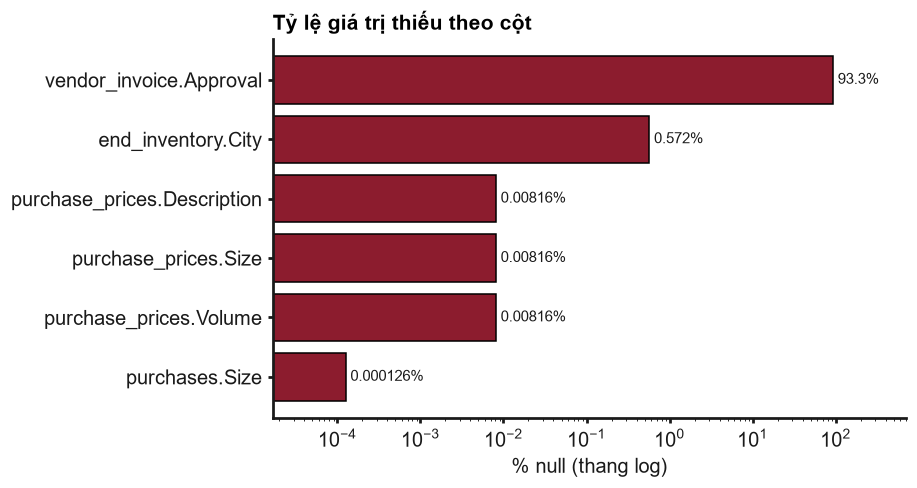

,col,n_null,null_pct
66,vendor_invoice.Approval,5169,93.25
11,end_inventory.City,1284,0.57
19,purchase_prices.Description,1,0.01
21,purchase_prices.Size,1,0.01
22,purchase_prices.Volume,1,0.01
31,purchases.Size,3,0.00


In [9]:
miss = (profile[profile["n_null"] > 0]
        .assign(col=lambda d: d["table_name"] + "." + d["column_name"])
        .sort_values("null_pct", ascending=False))
fig, (ax,) = viz.new_figure(figsize=(8.5, 0.5 * len(miss) + 1.6))
viz.barh(ax, miss["col"], miss["null_pct"], color=PALETTE["wine"], annotate="{:.3g}%")
ax.set_xscale("log")
viz.label(ax, "Tỷ lệ giá trị thiếu theo cột", "% null (thang log)")
viz.save_figure(fig, "01_missing_values")
plt.show()
miss[["col", "n_null", "null_pct"]]

**Biểu đồ 1.3 — Độ đa dạng (cardinality) của các cột khóa.** % giá trị khác nhau/tổng dòng
giúp nhận ra khóa chính (≈ 100 %) và cột phân loại (≈ 0 %).

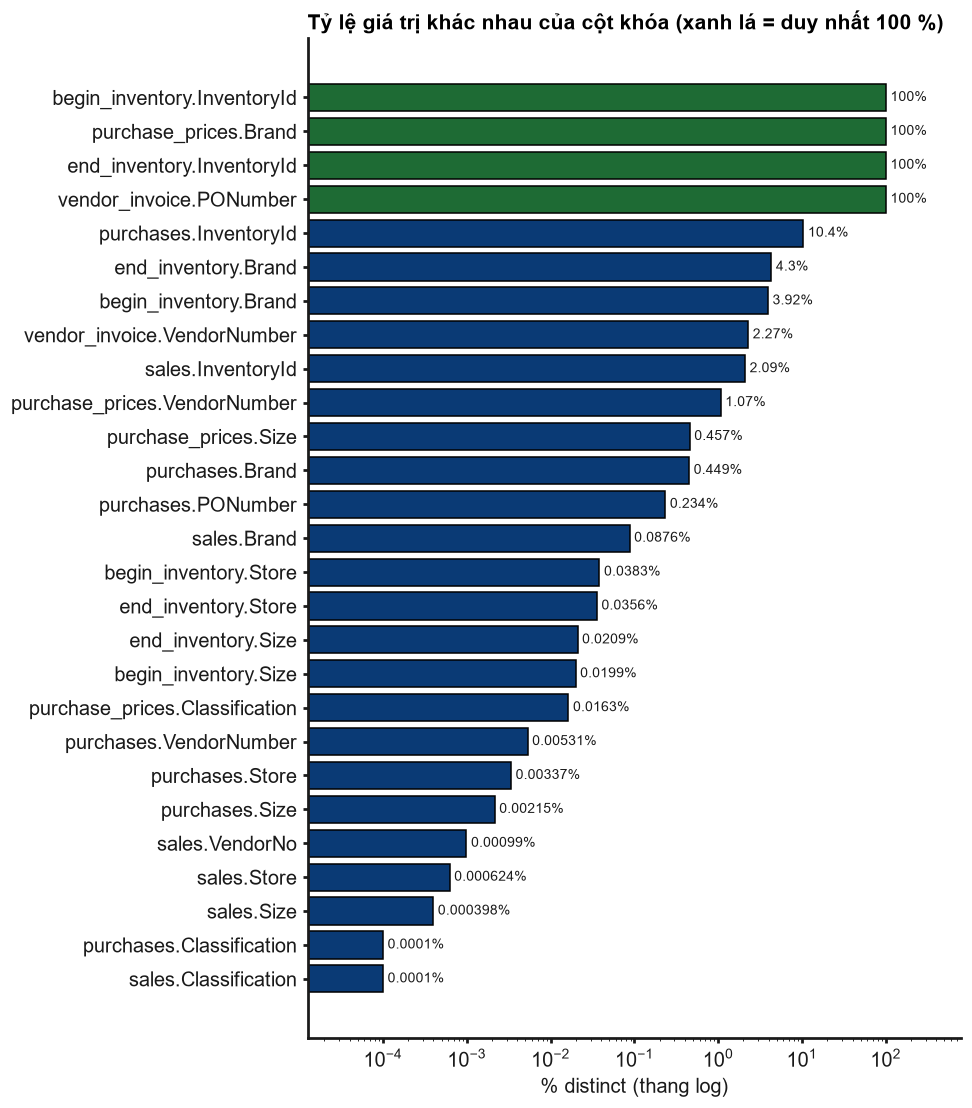

In [10]:
keys = ["InventoryId", "Brand", "Store", "VendorNumber", "VendorNo", "PONumber", "Classification", "Size"]
card = (profile[profile["column_name"].isin(keys)]
        .assign(col=lambda d: d["table_name"] + "." + d["column_name"])
        .sort_values("distinct_pct", ascending=False))
fig, (ax,) = viz.new_figure(figsize=(9, 0.32 * len(card) + 1.6))
viz.barh(ax, card["col"], card["distinct_pct"].clip(lower=1e-4),
         color=[PALETTE["green"] if v > 99.99 else PALETTE["blue"] for v in card["distinct_pct"]],
         annotate="{:.3g}%", fontsize=9)
ax.set_xscale("log")
viz.label(ax, "Tỷ lệ giá trị khác nhau của cột khóa (xanh lá = duy nhất 100 %)", "% distinct (thang log)")
viz.save_figure(fig, "01_key_cardinality")
plt.show()

Các cột chuỗi bị **đệm khoảng trắng** (thường là `VendorName`) — cần `TRIM` trước khi
join/group; phần này đã xử lý trong `sql/build/01_dimensions.sql`.

In [11]:
profile.loc[profile["n_untrimmed"] > 0, ["table_name", "column_name", "n_rows", "n_untrimmed"]]

,table_name,column_name,n_rows,n_untrimmed
26,purchase_prices,VendorName,12261,10407
33,purchases,VendorName,2372474,2170689
56,sales,VendorName,12825363,11719199
58,vendor_invoice,VendorName,5543,5133


Cột số có **giá trị 0** (giá = 0, tồn kho = 0, …) — dấu hiệu hàng tặng/khuyến mãi hoặc lỗi
nhập liệu, cần gắn cờ khi tính giá trung bình.

In [12]:
zeros = profile.loc[profile["n_zero"] > 0, ["table_name", "column_name", "n_rows", "n_zero"]]
zeros.assign(zero_pct=zeros["n_zero"] / zeros["n_rows"] * 100)

,table_name,column_name,n_rows,n_zero,zero_pct
6,begin_inventory,onHand,206529,6044,2.93
7,begin_inventory,Price,206529,2,0.00
15,end_inventory,onHand,224489,7230,3.22
20,purchase_prices,Price,12261,2,0.02
24,purchase_prices,PurchasePrice,12261,1,0.01
39,purchases,PurchasePrice,2372474,153,0.01
41,purchases,Dollars,2372474,153,0.01
49,sales,SalesDollars,12825363,55,0.00
50,sales,SalesPrice,12825363,55,0.00


## 4. Danh mục vấn đề chất lượng dữ liệu
Bảng `dq_checks` (tạo bởi `sql/build/06_quality_checks.sql`) đánh số theo mục §4 của
`data/data_dictionary.md`.

Hiển thị toàn bộ kiểm tra kèm số dòng bị ảnh hưởng, tỷ lệ và hướng xử lý.

In [13]:
dq = dl.query("dq_checks")
dq.to_csv(TABLE_DIR / "01_dq_checks.csv", index=False)
pp.style_table(dq, num=["n_affected", "n_total"], dec=["affected_pct"])

check_id,check_name,table_name,n_affected,n_total,affected_pct,action
1,1 mã NCC có nhiều cách viết tên,dim_vendor,2,132,1.52,Lấy 1 tên chuẩn theo VendorNumber
1,VendorName có khoảng trắng thừa,purchase_prices,"10,407","12,261",84.88,TRIM()
1,VendorName có khoảng trắng thừa,vendor_invoice,"5,133","5,543",92.60,TRIM()
4,Volume không phải số (Unknown/NULL),purchase_prices,5,"12,261",0.04,"Ép kiểu số, lỗi → NULL"
5,City bị thiếu,end_inventory,"1,284","224,489",0.57,Điền theo Store từ begin_inventory
6,Price = 0 (danh mục),purchase_prices,2,"12,261",0.02,Gắn cờ
6,PurchasePrice = 0,purchases,153,"2,372,474",0.01,Gắn cờ / loại khi tính giá vốn
6,SalesPrice = 0,sales,55,"12,825,363",0.00,Gắn cờ / loại khi tính giá bán
7,Approval rỗng,vendor_invoice,"5,169","5,543",93.25,"Coi là “chưa ghi nhận”, không impute"
8,Sau ghép: SL/tiền hóa đơn ≠ tổng dòng mua,mart_po,0,"5,543",0.00,Kỳ vọng = 0


**Biểu đồ 1.4 — Mức độ ảnh hưởng của từng vấn đề.** Đỏ đậm = vấn đề > 10 % số dòng
(cần xử lý trước khi phân tích), xanh = vấn đề nhỏ/biên.

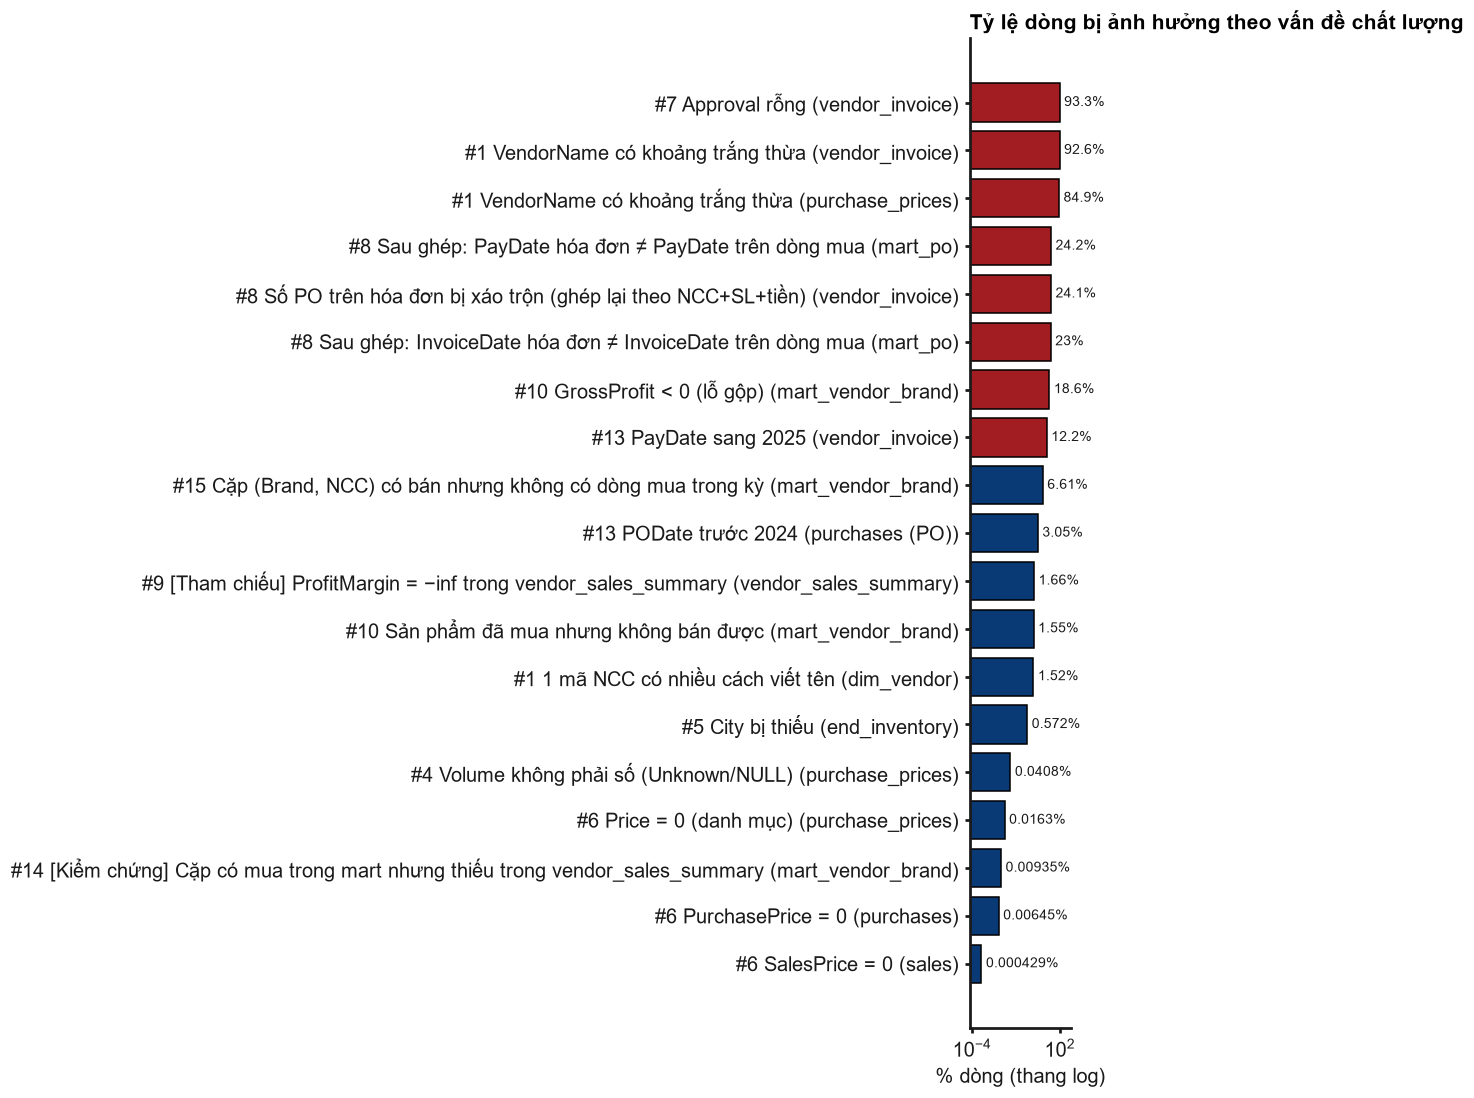

In [14]:
d = dq[dq["n_affected"] > 0].assign(lbl=lambda x: "#" + x["check_id"].astype(str) + " " + x["check_name"]
                                       + " (" + x["table_name"] + ")").sort_values("affected_pct", ascending=False)
fig, (ax,) = viz.new_figure(figsize=(10, 0.45 * len(d) + 1.6))
viz.barh(ax, d["lbl"], d["affected_pct"],
         color=[PALETTE["red"] if v > 10 else PALETTE["blue"] for v in d["affected_pct"]],
         annotate="{:.3g}%", fontsize=9)
ax.set_xscale("log")
viz.label(ax, "Tỷ lệ dòng bị ảnh hưởng theo vấn đề chất lượng", "% dòng (thang log)")
viz.save_figure(fig, "01_dq_issues")
plt.show()

## 5. Kiểm tra ngày tháng
Bảng `dq_dates` (tạo bởi `sql/build/08_consistency_checks.sql`) kiểm từng cột ngày của mọi file:
định dạng `YYYY-MM-DD` có hợp lệ không (dùng `date(v) = v`, bắt được cả ngày không tồn tại như 2024-02-30),
khoảng min–max, số ngày khác nhau và số dòng nằm ngoài năm 2024.

Hồ sơ 10 cột ngày trong 6 file nguồn.

In [15]:
dates = dl.query("dq_dates")
dates.to_csv(TABLE_DIR / "01_date_profile.csv", index=False)
pp.style_table(dates, num=["n_rows", "n_null", "n_bad_format", "n_distinct_days", "n_before_2024", "n_after_2024"],
               dec=["outside_2024_pct"])

table_name,column_name,n_rows,n_null,n_bad_format,min_date,max_date,n_distinct_days,n_before_2024,n_after_2024,outside_2024_pct
begin_inventory,startDate,"206,529",0,0,2024-01-01,2024-01-01,1,0,0,0.00
end_inventory,endDate,"224,489",0,0,2024-12-31,2024-12-31,1,0,0,0.00
purchases,InvoiceDate,"2,372,474",0,0,2024-01-04,2025-01-10,373,0,"79,665",3.36
purchases,PODate,"2,372,474",0,0,2023-12-20,2024-12-23,319,"47,050",0,1.98
purchases,PayDate,"2,372,474",0,0,2024-02-04,2025-02-19,382,0,"320,901",13.53
purchases,ReceivingDate,"2,372,474",0,0,2024-01-01,2024-12-31,364,0,0,0.00
sales,SalesDate,"12,825,363",0,0,2024-01-01,2024-12-31,364,0,0,0.00
vendor_invoice,InvoiceDate,"5,543",0,0,2024-01-04,2025-01-10,373,0,140,2.53
vendor_invoice,PODate,"5,543",0,0,2023-12-20,2024-12-23,319,169,0,3.05
vendor_invoice,PayDate,"5,543",0,0,2024-02-04,2025-02-19,382,0,677,12.21


**Biểu đồ 1.5 — Khoảng thời gian của từng cột ngày.** Vùng xám là năm phân tích 2024; thanh đỏ rượu
là cột có ngày ngoài 2024 (chứng từ vắt kỳ: đặt hàng cuối 2023, hóa đơn/thanh toán đầu 2025).

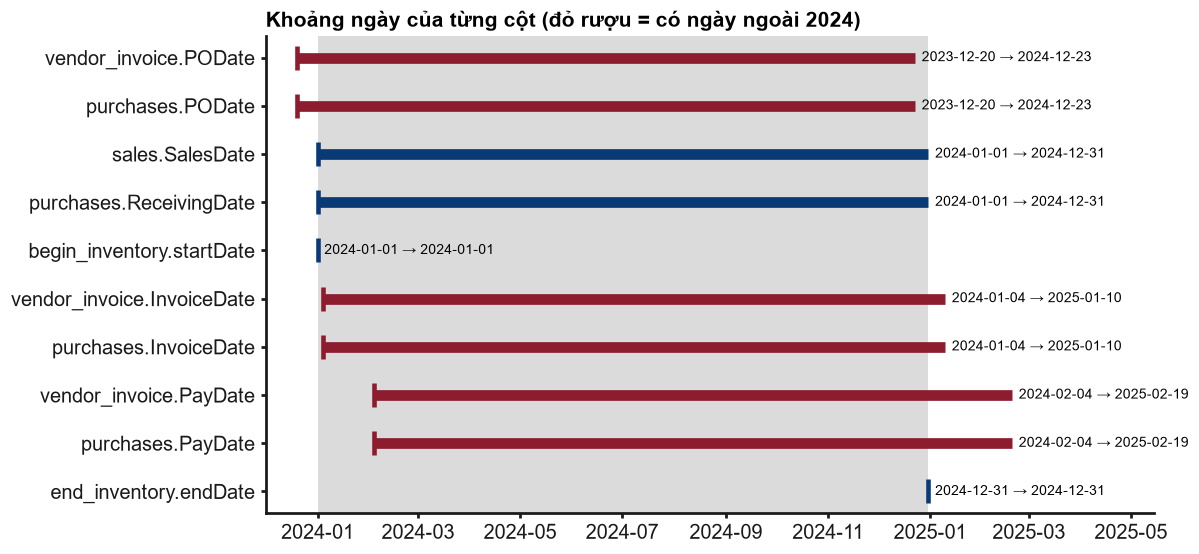

In [16]:
d = dates.assign(lbl=lambda x: x["table_name"] + "." + x["column_name"],
                 lo=lambda x: pd.to_datetime(x["min_date"]), hi=lambda x: pd.to_datetime(x["max_date"]))
d = d.sort_values("lo", ascending=False).reset_index(drop=True)
fig, (ax,) = viz.new_figure(figsize=(11, 5.2))
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"), color=PALETTE["light_gray"], alpha=0.35, lw=0)
for i, r in d.iterrows():
    out = (r["n_before_2024"] + r["n_after_2024"]) > 0
    ax.plot([r["lo"], r["hi"]], [i, i], color=PALETTE["wine"] if out else PALETTE["blue"], lw=7, solid_capstyle="butt")
    ax.plot([r["lo"]], [i], marker="|", ms=16, mew=3, color=PALETTE["wine"] if out else PALETTE["blue"])
    ax.text(r["hi"] + pd.Timedelta(days=4), i, f"{r['min_date']} → {r['max_date']}", va="center", fontsize=9)
ax.set_yticks(range(len(d)), d["lbl"])
ax.set_xlim(pd.Timestamp("2023-12-01"), pd.Timestamp("2025-05-15"))
viz.label(ax, "Khoảng ngày của từng cột (đỏ rượu = có ngày ngoài 2024)")
viz.save_figure(fig, "01_date_ranges")
plt.show()

**Biểu đồ 1.6 — Lịch doanh thu 2024 (năm nhuận, 366 ngày).** Mỗi ô là 1 ngày (cột = tuần, hàng = thứ);
màu càng đậm doanh thu càng cao. Dấu **X đỏ** = ngày *không có dòng bán nào*; vòng tròn cam = ngày không nhận hàng.

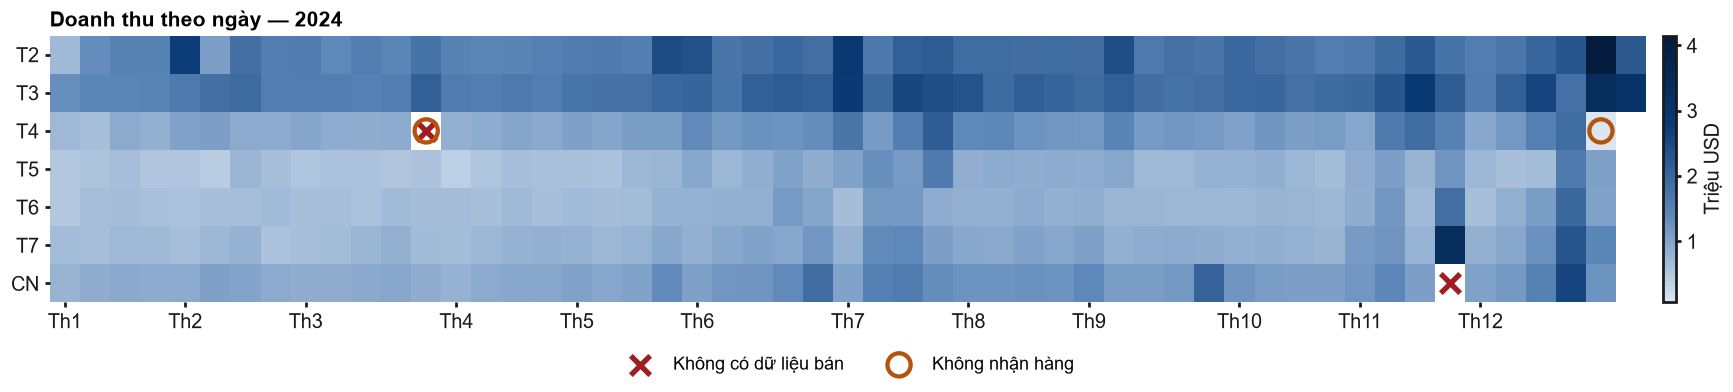

,day,weekday,has_sales,has_receiving,sales_dollars,receiving_dollars
86,2024-03-27,3,0,0,0.00,0.00
328,2024-11-24,0,0,1,0.00,109.68
359,2024-12-25,3,1,0,"63,025.15",0.00


In [17]:
cal = pp.parse_dates(dl.query("dq_calendar"), ["day"])
first_offset = (cal["day"].iloc[0].dayofweek)            # 0 = thứ 2
cal["week"] = (cal["day"].dt.dayofyear - 1 + first_offset) // 7
cal["row"] = cal["day"].dt.dayofweek                      # 0 = T2 … 6 = CN
mat = cal.pivot(index="row", columns="week", values="sales_dollars").replace(0, np.nan) / 1e6
fig, (ax,) = viz.new_figure(figsize=(16, 3.8))
im = ax.imshow(mat, aspect="auto", cmap=viz.CMAP_SEQ)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="Triệu USD")
miss_s = cal[~cal["has_sales"].astype(bool)]
miss_r = cal[~cal["has_receiving"].astype(bool)]
ax.scatter(miss_s["week"], miss_s["row"], marker="x", s=160, color=PALETTE["red"], lw=3.5, label="Không có dữ liệu bán")
ax.scatter(miss_r["week"], miss_r["row"], marker="o", s=230, facecolor="none", edgecolor=PALETTE["orange"], lw=2.8,
           label="Không nhận hàng")
ax.set_yticks(range(7), ["T2", "T3", "T4", "T5", "T6", "T7", "CN"])
starts = cal.groupby(cal["day"].dt.month)["week"].min()
ax.set_xticks(starts.values, pp.MONTH_VI)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
viz.label(ax, "Doanh thu theo ngày — 2024")
viz.save_figure(fig, "01_sales_calendar")
plt.show()
cal.loc[~cal["has_sales"].astype(bool) | ~cal["has_receiving"].astype(bool),
        ["day", "weekday", "has_sales", "has_receiving", "sales_dollars", "receiving_dollars"]]

## 6. Nhất quán giữa các file
`dq_consistency` gom 39 kiểm tra chéo giữa 6 file, chia nhóm: ngày tháng, khóa & liên kết, tồn kho, thuộc tính
sản phẩm, nhà cung cấp, giá, số học, hóa đơn. Mức độ: **Lỗi** (phải xử lý trước khi phân tích),
**Cảnh báo** (khác biệt có giải thích / cần lưu ý), **Đạt** (0 vi phạm).

Toàn bộ kiểm tra, xếp Lỗi → Cảnh báo → Đạt. Lưu ra `reports/table/01_consistency_checks.csv`.

In [18]:
cons = dl.query("dq_consistency")
cons.to_csv(TABLE_DIR / "01_consistency_checks.csv", index=False)
pp.style_table(cons.drop(columns=["tables"]), num=["n_affected", "n_total"], dec=["affected_pct"])

check_group,check_name,n_affected,n_total,affected_pct,severity,note
Hóa đơn,Số PO trên hóa đơn không khớp PO thật (đã ghép lại theo NCC+SL+tiền),"1,336","5,543",24.10,Lỗi,Từ PO 12311 (PODate ≥ 25/09/2024); PODate hóa đơn lệch ±5 ngày
Giá,Giá bán (sales) khác giá niêm yết danh mục,"5,950,335","12,825,363",46.40,Cảnh báo,Giá bán thay đổi theo thời gian/cửa hàng; danh mục là giá tham chiếu — tính doanh thu từ SalesDollars
Giá,Giá tồn đầu kỳ khác giá niêm yết danh mục,"88,356","206,529",42.78,Cảnh báo,Giá thời điểm 01/01
Giá,Giá tồn cuối kỳ khác giá niêm yết danh mục,"112,525","224,489",50.12,Cảnh báo,Giá thời điểm 31/12
Hóa đơn,Ngày hóa đơn / ngày trả trên hóa đơn ≠ ngày ghi trên dòng mua,"1,403","5,543",25.31,Cảnh báo,pay_days dùng ngày trên hóa đơn
Hóa đơn,PO giao nhiều đợt (≥ 2 ngày nhận) — không phải dòng trùng,"5,000","5,543",90.20,Cảnh báo,"Giải thích các cặp (PONumber, InventoryId) lặp lại"
Khóa & liên kết,InventoryId có giao dịch nhưng không có trong ảnh chụp tồn kho đầu/cuối kỳ,"20,347","276,389",7.36,Cảnh báo,Mua vào và bán hết trong năm (tồn = 0 ở cả 2 mốc) — cân đối vẫn khớp
Ngày tháng,"Ngày chứng từ ngoài 2024 (PODate 2023, Invoice/PayDate 2025)","448,602","7,134,051",6.29,Cảnh báo,Hợp lệ: đơn vắt qua đầu/cuối kỳ
Ngày tháng,"Ngày trong năm KHÔNG có dữ liệu bán: 2024-03-27, 2024-11-24",2,366,0.55,Cảnh báo,Năm nhuận 366 ngày; ngày thiếu làm giảm doanh thu tháng tương ứng
Ngày tháng,"Ngày trong năm KHÔNG có nhận hàng: 2024-03-27, 2024-12-25",2,366,0.55,Cảnh báo,Nhận hàng diễn ra cả cuối tuần


**Biểu đồ 1.7 — Kết quả kiểm tra nhất quán theo nhóm** (số kiểm tra Đạt / Cảnh báo / Lỗi).

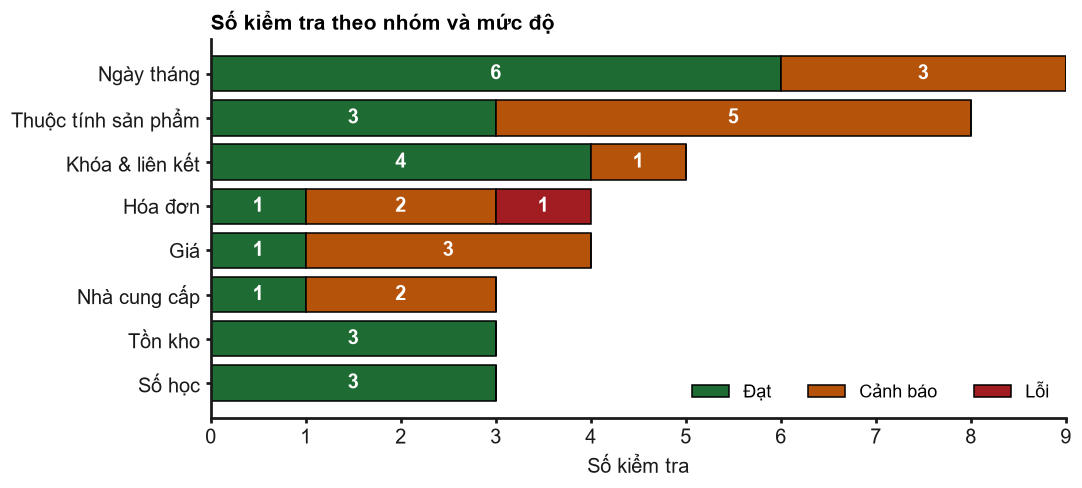

In [19]:
cnt = (cons.groupby(["check_group", "severity"]).size().unstack(fill_value=0)
       .reindex(columns=["Đạt", "Cảnh báo", "Lỗi"], fill_value=0))
cnt = cnt.loc[cnt.sum(axis=1).sort_values().index]
fig, (ax,) = viz.new_figure(figsize=(10, 4.6))
left = np.zeros(len(cnt))
for sev, col in zip(cnt.columns, [PALETTE["green"], PALETTE["orange"], PALETTE["red"]]):
    bars = ax.barh(cnt.index, cnt[sev], left=left, color=col, edgecolor="black", linewidth=1, label=sev)
    ax.bar_label(bars, labels=[str(v) if v else "" for v in cnt[sev]], label_type="center",
                 color="white", fontweight="bold")
    left += cnt[sev].to_numpy()
ax.legend(ncol=3, loc="lower right")
viz.label(ax, "Số kiểm tra theo nhóm và mức độ", "Số kiểm tra")
viz.save_figure(fig, "01_consistency_summary")
plt.show()

### 6.1. Phát hiện quan trọng: số PO trên `vendor_invoice` bị xáo trộn
Từ PO 12311 (đặt từ 25/09/2024), hóa đơn mang số PO **không khớp** PO thật: NCC, số lượng và tiền trên hóa đơn
thuộc về một PO *khác* đặt cùng thời điểm. Nối thẳng theo `PONumber` sẽ gán phí vận chuyển cho sai NCC.
`sql/build/03_purchase_marts.sql` ghép lại hóa đơn theo khóa nghiệp vụ **(NCC, số lượng, tiền)** + ngày đặt gần
nhất → bảng `map_invoice_po`; mọi mart nối hóa đơn qua bảng này.

**Biểu đồ 1.8 — (a)** số PO theo tháng đặt hàng và cách ghép hóa đơn; **(b)** độ lệch PODate
(hóa đơn − dòng mua) của nhóm phải ghép lại.

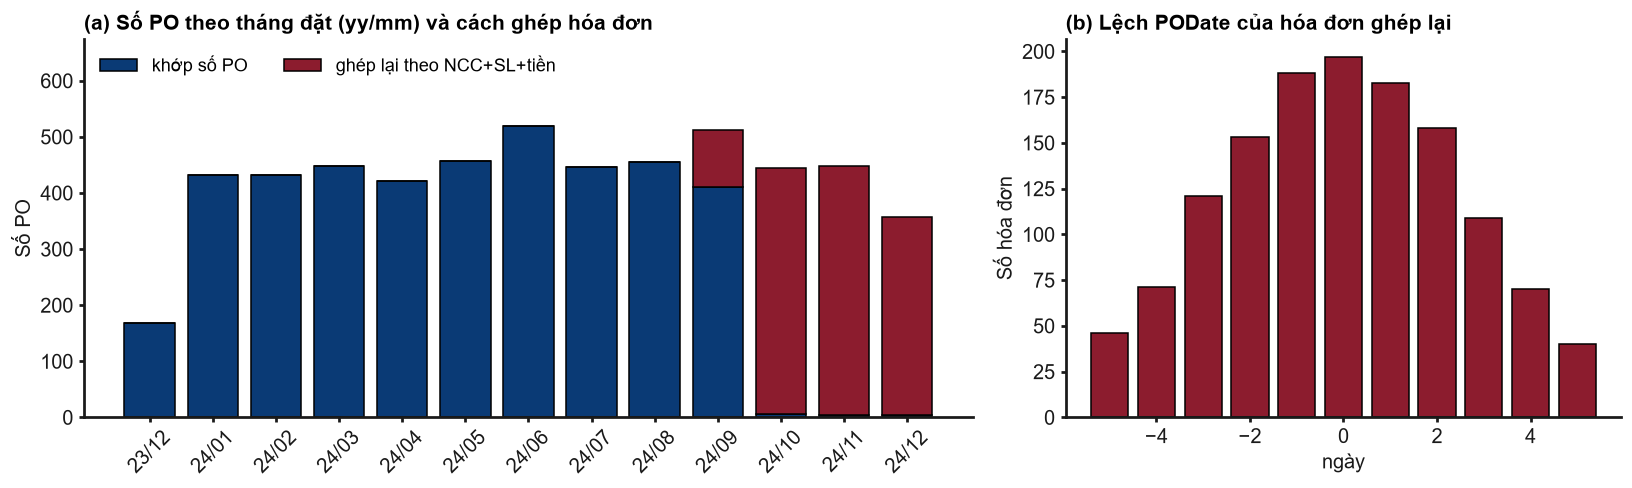

match_type,ghép lại theo NCC+SL+tiền,khớp số PO,pct_rematched
POMonth,,,
2024-08,0,456,0.00
2024-09,101,411,19.73
2024-10,438,6,98.65
2024-11,444,4,99.11
2024-12,353,5,98.60


In [20]:
im_ = dl.query("invoice_match")
piv = im_.pivot_table(index="POMonth", columns="match_type", values="n_po", aggfunc="sum", fill_value=0)
shift = dl.query("invoice_shift")
fig, axes = viz.new_figure(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
labels = [f"{m[2:4]}/{m[5:7]}" for m in piv.index]          # 'yy/mm' vì có tháng 12/2023
bottom = np.zeros(len(piv))
for col, c in zip(["khớp số PO", "ghép lại theo NCC+SL+tiền"], [PALETTE["blue"], PALETTE["wine"]]):
    if col in piv:
        axes[0].bar(labels, piv[col], bottom=bottom, color=c, edgecolor="black", lw=1, label=col)
        bottom += piv[col].to_numpy()
axes[0].set_ylim(0, piv.sum(axis=1).max() * 1.3)
axes[0].legend(loc="upper left", ncol=2)
axes[0].tick_params(axis="x", rotation=45)
viz.label(axes[0], "(a) Số PO theo tháng đặt (yy/mm) và cách ghép hóa đơn", None, "Số PO")
s_ = shift[shift["match_type"] != "khớp số PO"]["podate_shift_days"].value_counts().sort_index()
axes[1].bar(s_.index, s_.values, color=PALETTE["wine"], edgecolor="black", lw=1)
viz.label(axes[1], "(b) Lệch PODate của hóa đơn ghép lại", "ngày", "Số hóa đơn")
viz.save_figure(fig, "01_invoice_rematch")
plt.show()
piv.assign(pct_rematched=lambda x: x.get("ghép lại theo NCC+SL+tiền", 0) / x.sum(axis=1) * 100).tail(5)

Các kiểm tra hóa đơn trong `dq_checks` **sau khi ghép lại**: không còn lệch số lượng/tiền; phí vận chuyển
theo NCC khớp `vendor_sales_summary` ở mọi NCC (nếu nối thẳng theo `PONumber` chỉ khớp 9/126 NCC).

In [21]:
dl.query("dq_checks").query("check_id in (8, 14)")[["check_id", "check_name", "n_affected", "n_total", "action"]]

,check_id,check_name,n_affected,n_total,action
9,8,Sau ghép: SL/tiền hóa đơn ≠ tổng dòng mua,0,5543,Kỳ vọng = 0
10,8,Sau ghép: InvoiceDate hóa đơn ≠ InvoiceDate tr...,1273,5543,pay_days tính theo ngày trên hóa đơn
11,8,Sau ghép: PayDate hóa đơn ≠ PayDate trên dòng mua,1339,5543,pay_days tính theo ngày trên hóa đơn
12,8,Số PO trên hóa đơn bị xáo trộn (ghép lại theo ...,1336,5543,"Nối hóa đơn qua map_invoice_po, không theo PON..."
13,8,Hóa đơn không ghép được với PO nào,0,5543,Kỳ vọng = 0
19,14,[Kiểm chứng] Cặp có mua trong mart nhưng thiếu...,1,10693,Giải thích từng dòng
20,14,[Kiểm chứng] Phí vận chuyển theo NCC lệch Frei...,0,126,Kỳ vọng = 0
21,14,[Kiểm chứng] mart_vendor_brand lệch vendor_sal...,0,10692,Kỳ vọng = 0
22,14,[Kiểm chứng] Cặp trong vendor_sales_summary nh...,0,10692,Kỳ vọng = 0


### 6.2. Cân đối tồn kho: đầu kỳ + mua − bán = cuối kỳ
`mart_stock_flow` cân đối từng `InventoryId` (cửa hàng × sản phẩm) giữa 4 file: `begin_inventory`, `purchases`,
`sales`, `end_inventory`.

Tổng hợp theo nhóm mặt hàng có / không có trong ảnh chụp tồn kho đầu–cuối kỳ.

In [22]:
pp.style_table(dl.query("stock_flow_summary"),
               num=["n_items", "begin_onhand", "purchased", "sold", "end_onhand", "gap", "n_items_gap"])

item_group,n_items,begin_onhand,purchased,sold,end_onhand,gap,n_items_gap
Có trong ảnh chụp tồn kho,"256,042","4,219,275","32,627,275","31,960,774","4,885,776",0,0
Không có trong ảnh chụp tồn kho,"20,347",0,"957,102","957,102",0,0,0


## 7. Kiểm chứng kết quả tự tính
`mart_vendor_brand` được tính hoàn toàn từ `purchases.csv` + `sales.csv` + `purchase_prices.csv` +
`vendor_invoice.csv`. File `vendor_sales_summary.csv` **chỉ dùng ở đây** để đối chiếu, xác nhận logic SQL
đúng (số cặp lệch kỳ vọng = 0); không phân tích nào lấy số liệu từ file này.

Đếm số cặp (NCC, Brand) khớp và số cặp lệch ở từng chỉ tiêu (ngưỡng $0,01).

In [23]:
dl.query("vss_comparison")

,n_matched,n_purchase_diff,n_sales_diff,n_sales_qty_diff,n_gross_profit_diff,n_vss_rows,n_mart_rows_with_purchase,n_mart_rows_sales_only
0,10692,0,0,0,0,10692,10693,757


Thông tin build (thời điểm, thời gian chạy) để ghi vào báo cáo tái lập.

In [24]:
dl.read_table("build_info")

,built_at,seconds,source
0,2026-11-25T01:11:58,589.67,CSV trong D:\2026.1\Kho dữ liệu\data\raw (qua ...


## 8. Nhận xét

1. **Quy mô:** `sales` (12,8 triệu dòng) và `purchases` (2,37 triệu) chiếm gần hết dung lượng; mọi
   bảng khác < 230 nghìn dòng ⇒ chiến lược *tổng hợp trước bằng SQL → phân tích trên mart* là hợp lý:
   `analytics.db` ~89 MB, mỗi truy vấn notebook chạy trong mili-giây.
2. **Thiếu dữ liệu rất ít**, trừ `vendor_invoice.Approval` (93,3 % rỗng — coi là “không ghi nhận”) và
   `end_inventory.City` (1 284 dòng, toàn bộ Store 46 — đã điền lại trong `dim_store`).
3. **Ngày tháng sạch về định dạng và thứ tự:** 22,8 triệu giá trị ngày đều đúng `YYYY-MM-DD` và tồn tại;
   không có ngày bán/nhận hàng ngoài 2024; thứ tự đặt → nhận → hóa đơn → thanh toán luôn đúng. Chứng từ vắt kỳ
   là hợp lệ (PODate từ 20/12/2023; InvoiceDate/PayDate đến 02/2025).
   **Nhưng thiếu ngày:** 2024 có 366 ngày, `sales` chỉ có 364 — **không có dòng bán nào ngày 27/03 (T4) và
   24/11 (CN)**; ngày 27/03 cũng không có nhận hàng (25/12 không nhận hàng là hợp lý). Nhiều khả năng mất dữ
   liệu ngày 27/03 ⇒ khi so sánh theo ngày/tuần cần lưu ý; doanh thu tháng 3 và 11 thấp đi tương ứng.
4. **Lỗi nghiêm trọng nhất — số PO trên hóa đơn bị xáo trộn** (1 336/5 543 hóa đơn, toàn bộ từ PO 12311,
   đặt từ 25/09/2024): NCC/số lượng/tiền trên hóa đơn thuộc về PO khác đặt cùng thời điểm, PODate lệch ±5 ngày,
   ngày hóa đơn/thanh toán cũng khác. Đã **ghép lại 100 %** theo (NCC, số lượng, tiền) + ngày gần nhất. Sau
   khi sửa: không còn lệch số lượng/tiền, phí vận chuyển theo NCC khớp tham chiếu 126/126 NCC. Đây chính là
   nguyên nhân của “~24 % PO lệch hóa đơn” ghi trong `data_dictionary.md`.
5. **Tồn kho cân đối tuyệt đối:** với cả 276 389 `InventoryId`, đầu kỳ + mua − bán = cuối kỳ (lệch 0 chai),
   không mặt hàng nào bán vượt lượng sẵn có. 20 347 `InventoryId` có giao dịch nhưng không nằm trong ảnh chụp
   tồn kho là hàng **mua vào và bán hết trong năm** (957 102 chai mua = 957 102 chai bán) — không phải lỗi.
   Cân đối hoàn hảo cho thấy đây là dữ liệu mô phỏng (không có hao hụt/mất mát).
6. **Khác biệt thuộc tính giữa file (cảnh báo, không phải lỗi):**
   * `Size` viết khác nhau giữa danh mục (`1500mL`) và giao dịch/tồn kho (`1.5L`, `Liter`) ở ~1 400 sản phẩm —
     cùng dung tích; chỉ 33 sản phẩm khác dung tích thật (gói nhiều chai). Dùng `Volume` khi cần số.
   * `Description` trong tồn kho đầu kỳ khác danh mục ở 2 755 dòng (“Glass Pack” ↔ “VAP”) ⇒ luôn nối theo `Brand`.
   * 91 trường hợp Brand được bán/mua dưới mã NCC khác danh mục; 2 mã NCC có 2 tên (đổi tên/sáp nhập).
   * **Giá danh mục chỉ là giá tham chiếu:** giá bán khác giá niêm yết ở 46 % dòng bán, giá tồn kho khác ở
     43–50 % dòng ⇒ doanh thu luôn lấy từ `SalesDollars`, giá trị tồn kho theo giá của chính ảnh chụp.
     Ngược lại, giá mua trong `purchases` **luôn đúng** giá mua danh mục.
7. **Số học và khóa hoàn toàn sạch:** thành tiền = đơn giá × số lượng ở 15,2 triệu dòng; không trùng khóa,
   không Brand mồ côi, `InventoryId` luôn đúng mẫu `Store_City_Brand`, mỗi Store đúng 1 City; thuế tiêu thụ
   ≈ 1,05 USD/lít (rượu mạnh) và ≈ 0,15 USD/lít (vang).
8. **Kiểm chứng:** `mart_vendor_brand` tự tính từ CSV nguồn **khớp 100 %** với `vendor_sales_summary.csv`
   (10 692/10 692 cặp, 0 lệch ở tiền mua, doanh thu, số lượng bán, lợi nhuận gộp, phí vận chuyển theo NCC).
   Mart thừa 1 cặp có mua (Brand 2166, tiền mua = 0 — bảng tham chiếu đã loại) và thêm 757 cặp *chỉ có bán*
   (bán từ tồn đầu kỳ) — giữ lại để tổng doanh thu khớp đúng `sales.csv` (452,06 triệu USD).